# exp02: Perbandingan Algoritma

Membandingkan Logistic Regression, SVM RBF, Random Forest, Extra Trees, XGBoost, dan CatBoost pada fitur original. Parameter tiap model dipilih dari registry yang sama seperti batch-01 lama, menggunakan tiga inner fold berbasis peserta.

Dataset: good_acceptable, window 45 detik, langkah 5 detik. Target dibaca langsung dari cognitive_load_label (Low=0, Medium=1, High=2), termasuk Low pada fase nonpengerjaan yang sudah diberi label dalam dataset v2. Identitas, konteks CodeArrange, dan kualitas hanya menjadi metadata/pembagi evaluasi, bukan fitur prediksi.

### Konfigurasi

Memakai runtime lokal yang sudah diverifikasi terhadap artefak batch-01 lama. Run ini mengevaluasi seluruh peserta dengan seed 42 dan 300 tree/iterasi untuk model berbasis pohon. Checkpoint yang cocok dilanjutkan; hasil dengan identitas data, kode, atau environment berbeda tidak dicampur.

In [1]:
from pathlib import Path
import json
import sys

location = Path.cwd().resolve()
BATCH = next(p for p in (location, *location.parents) if (p / "shared" / "design_registry.json").is_file())
sys.path.insert(0, str(BATCH))

import pandas as pd
from IPython.display import display, Image
from shared import data, design
from shared.runner import Config, run

EXPERIMENT = "exp02"
WINDOW = "window_45s_step_5s"
DATASET_PATH = data.ROOT / "analysis_sessions" / "dataset_fusion" / "output" / "v2_session_phase" / WINDOW / "good_acceptable.csv"
config = Config(dataset_path=DATASET_PATH, output_root=BATCH / "outputs", experiment=EXPERIMENT)
print(DATASET_PATH)

D:\Penelitian Pak Hadi\Adaptive-IDE\analysis_sessions\dataset_fusion\output\v2_session_phase\window_45s_step_5s\good_acceptable.csv


### Dataset dan Kandidat

Memeriksa label, ID window, timestamp, dan allowlist sensor sebelum training. Tidak ada pemetaan ulang dari difficulty. Missing value dan fitur konstan ditangani pada training masing-masing fold, bukan secara global.

In [2]:
frame = data.load_dataset(DATASET_PATH)
display(pd.DataFrame(data.describe_data(frame)["class_counts"].items(), columns=["label", "windows"]))
specifications = design.registry(EXPERIMENT)
display(pd.DataFrame([{**{k: v for k, v in item.items() if k != "candidates"}, "candidate_count": len(item["candidates"])} for item in specifications]))
print(f"{len(frame)} windows; {frame.participant_id.nunique()} participants; {len(data.FEATURES)} base sensor features")

,label,windows
0,Low,614
1,Medium,650
2,High,854


,id,model,scaler,tune,variant,candidate_count
0,logistic,logistic,standard,True,original,6
1,svm,svm,standard,True,original,12
2,random_forest,random_forest,NaN,True,original,12
3,extra_trees,extra_trees,NaN,True,original,12
4,xgboost,xgboost,NaN,True,original,12
5,catboost,catboost,NaN,True,original,12


2118 windows; 13 participants; 26 base sensor features


### Fold dan Training

Leave-one-participant-out menghasilkan satu prediksi test untuk setiap window. Tiga inner group fold, bila diperlukan tuning, hanya menggunakan peserta training. Kriteria seleksi adalah macro-F1 gabungan prediksi inner; parameter terpilih lalu dilatih ulang pada seluruh outer training. Imputasi, scaler, feature selection, dan resampling tidak melihat outer test.

Cache menyimpan hasil fit/prediksi dengan hash data, urutan ID split, pipeline, parameter, seed, kode, dan paket. Hash output diperiksa sebelum melanjutkan checkpoint.

In [3]:
folds = data.make_folds(frame)
display(pd.DataFrame([{"fold": f["fold_id"], "test_participant": f["participant_id"], "train_windows": len(f["train"]), "test_windows": len(f["test"]), "inner_folds": len(f["inner"])} for f in folds]))
RESULT_DIR = run(config)
print(RESULT_DIR)

,fold,test_participant,train_windows,test_windows,inner_folds
0,fold_00,Andrean,1880,238,3
1,fold_01,Andreas,2035,83,3
2,fold_02,Athaya,1979,139,3
3,fold_03,Fabian,1902,216,3
4,fold_04,Rafi,1863,255,3
5,fold_05,Savitri,1916,202,3
6,fold_06,Shakilla,2054,64,3
7,fold_07,Tio,1943,175,3
8,fold_08,faqih,1900,218,3
9,fold_09,ikhsan,1906,212,3


Complete run verified: D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp02\window_45s_step_5s\full_75c71fd5b4a8


D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp02\window_45s_step_5s\full_75c71fd5b4a8


### Evaluasi

Macro-F1 pooled pada tiga kelas menjadi metrik utama. Accuracy, balanced accuracy, precision/recall/F1 per kelas, dan variasi antarorang melengkapi penilaian. Kelas tanpa contoh pada test seseorang tetap kosong pada laporan kelas, bukan dianggap performa nol.

In [4]:
metrics = pd.read_csv(RESULT_DIR / "metrics.csv").sort_values("macro_f1", ascending=False)
display(metrics)
classes = pd.read_csv(RESULT_DIR / "class_metrics.csv")
display(classes[classes.scope.eq("pooled")].drop(columns=["participant_id"], errors="ignore"))
display(pd.read_csv(RESULT_DIR / "participant_summary.csv", header=[0, 1], index_col=0))

,model,accuracy,balanced_accuracy,macro_f1,windows
3,random_forest,0.368272,0.358798,0.354142,2118
0,catboost,0.313503,0.321380,0.314121,2118
1,extra_trees,0.333805,0.323542,0.313757,2118
2,logistic,0.324835,0.320380,0.296703,2118
5,xgboost,0.288008,0.292488,0.288996,2118
4,svm,0.302644,0.299880,0.288481,2118


,scope,model,label,precision,recall,f1,support
0,pooled,catboost,Low,0.343915,0.423453,0.379562,614
1,pooled,catboost,Medium,0.250340,0.283077,0.265704,650
2,pooled,catboost,High,0.350877,0.257611,0.297097,854
42,pooled,extra_trees,Low,0.296010,0.374593,0.330697,614
43,pooled,extra_trees,Medium,0.288136,0.156923,0.203187,650
44,pooled,extra_trees,High,0.379939,0.439110,0.407387,854
84,pooled,logistic,Low,0.303665,0.472313,0.369662,614
85,pooled,logistic,Medium,0.219081,0.095385,0.132905,650
86,pooled,logistic,High,0.381818,0.393443,0.387543,854
126,pooled,random_forest,Low,0.335674,0.389251,0.360483,614


accuracy                     balanced_accuracy            \
                    min    median       max               min    median   
model                                                                     
catboost       0.000000  0.296296  0.483871          0.000000  0.333333   
extra_trees    0.000000  0.389908  0.596774          0.000000  0.333333   
logistic       0.046875  0.292079  0.505882          0.046875  0.333333   
random_forest  0.000000  0.380734  0.741935          0.000000  0.365550   
svm            0.000000  0.278261  0.536697          0.000000  0.328661   
xgboost        0.000000  0.297030  0.500000          0.000000  0.315042   

                         macro_f1                      
                    max       min    median       max  
model                                                  
catboost       0.578632  0.000000  0.236111  0.472126  
extra_trees    0.438859  0.000000  0.192308  0.383653  
logistic       0.419605  0.089552  0.189003  0.332646  
random_forest  0.492877  0.000000  0.312084  0.497407  
svm            0.492678  0.000000  0.206638  0.442096  
xgboost        0.383578  0.000000  0.228369  0.392765

### Confusion Matrix

Baris adalah label referensi, kolom adalah prediksi. Diagonal menunjukkan recall kelas pada gambar ternormalisasi. Maksimal enam model ditampilkan di notebook; seluruh confusion matrix tersimpan pada direktori hasil.

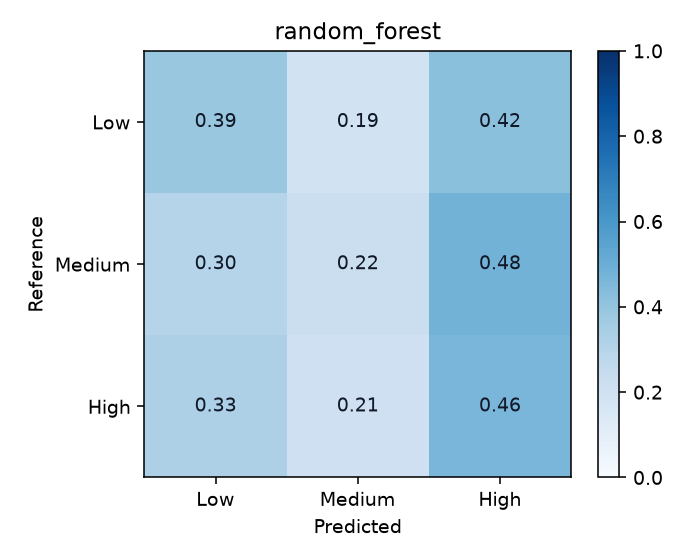

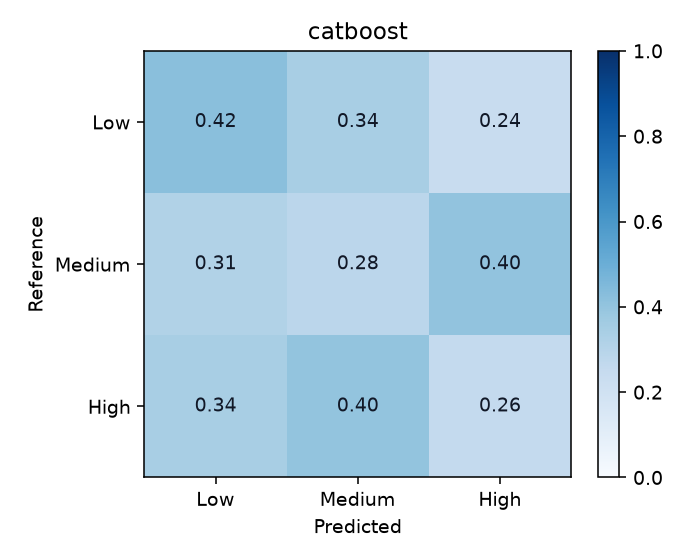

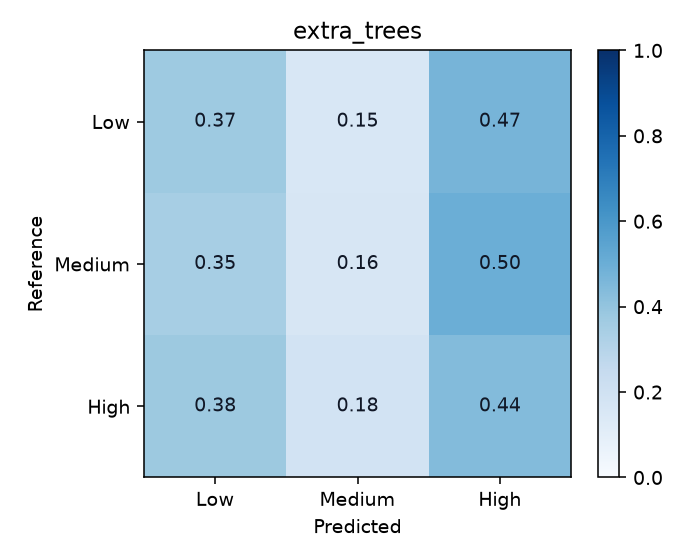

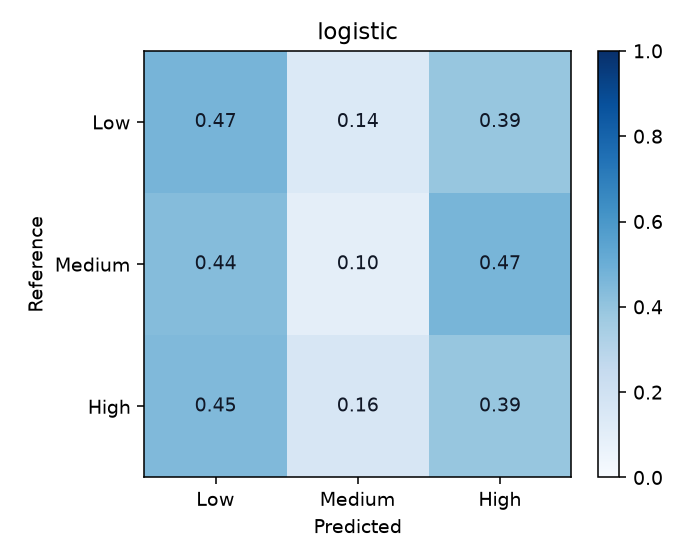

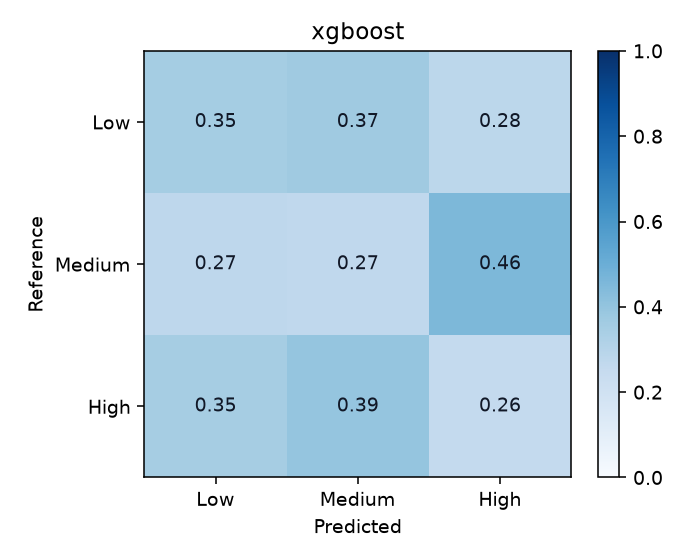

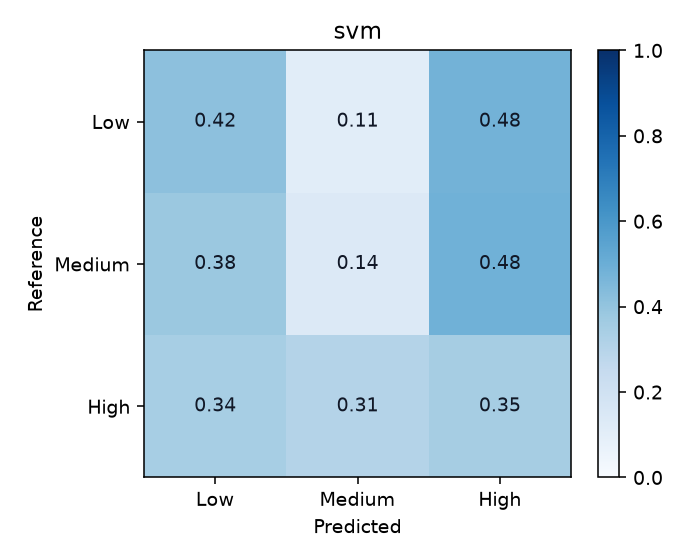

In [5]:
for name in metrics.model.head(6):
    display(Image(filename=str(RESULT_DIR / "figures" / f"{name}_normalized.png")))

### Artefak

Prediksi, manifest, pencarian kandidat, konfigurasi preprocessing, metrik, dan figure tersedia untuk audit. Bobot model dan cache disimpan lokal tetapi tidak masuk Git. Sumber dataset serta arsip old-dataset tidak diubah.

In [6]:
summary = json.loads((RESULT_DIR / "summary.json").read_text())
assert summary["status"] == "complete"
assert summary["evaluated_folds"] == frame.participant_id.nunique()
print(f"Status: {summary['status']}")
print(f"Output: {RESULT_DIR}")

Status: complete
Output: D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp02\window_45s_step_5s\full_75c71fd5b4a8
